In [17]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Python/GitHub/goals-championship/csv/fotmob_match_stats.csv')
df.head(2)

,matchId,matchRound,homeTeamName,homeTeamid,awayTeamName,awayTeamid,home_goals,away_goals,ball_possession_home,ball_possession_away,...,ground_duels_won_home,ground_duels_won_away,aerial_won_home,aerial_won_away,dribbles_succeeded_home,dribbles_succeeded_away,yellow_cards_home,yellow_cards_away,red_cards_home,red_cards_away
0,5836754,1,Wolverhampton Wanderers,8602,Blackburn Rovers,8655,2,2,55,45,...,40 (56%),31 (44%),15 (48%),16 (52%),8 (44%),7 (41%),1,3,0,0
1,5836755,1,Bolton Wanderers,8559,Preston North End,8411,2,1,55,45,...,30 (48%),33 (52%),18 (49%),19 (51%),5 (38%),6 (55%),2,3,0,0


In [18]:
df = df.drop(37).reset_index(drop=True)
df = df.drop(46).reset_index(drop=True)

In [19]:
# create a dataframe merging teams data
# home
home_df = df[['homeTeamName', 'homeTeamid', 'home_goals', 'xG_home']].rename(
    columns={
        'homeTeamName': 'teamName',
        'homeTeamid': 'teamId',
        'home_goals': 'goals',
        'xG_home': 'xG',
    }
)

# away
away_df = df[['awayTeamName', 'awayTeamid', 'away_goals', 'xG_away']].rename(
    columns={
        'awayTeamName': 'teamName',
        'awayTeamid': 'teamId',
        'away_goals': 'goals',
        'xG_away': 'xG',
    }
)

# stack both dataframes together
stack = pd.concat([home_df, away_df], ignore_index=True)

c_df = (
    stack
    .groupby(['teamId', 'teamName']).agg(
          matches=('teamName', 'size'),
          goals=('goals', 'sum'),
          xG=('xG', 'sum'),
      )
      .sort_values('goals', ascending=False)
      .reset_index()
)

c_df

,teamId,teamName,matches,goals,xG
0,8654,West Ham United,17,38,35.06
1,9850,Norwich City,17,35,27.37
2,8549,Middlesbrough,17,34,34.71
3,8466,Southampton,17,32,31.05
4,8602,Wolverhampton Wanderers,17,31,32.98
5,8658,Birmingham City,17,30,29.90
6,8659,West Bromwich Albion,17,28,31.06
7,8344,Cardiff City,17,28,32.44
8,10194,Stoke City,17,27,18.37
9,8657,Sheffield United,17,26,22.38


In [ ]:
df.columns

Index(['matchId', 'matchRound', 'homeTeamName', 'homeTeamid', 'awayTeamName',
       'awayTeamid', 'home_goals', 'away_goals', 'ball_possession_home',
       'ball_possession_away', 'big_chances_home', 'big_chances_away',
       'big_chances_missed_home', 'big_chances_missed_away', 'fouls_home',
       'fouls_away', 'corners_home', 'corners_away', 'total_shots_home',
       'total_shots_away', 'shots_off_target_home', 'shots_off_target_away',
       'shots_on_target_home', 'shots_on_target_away', 'blocked_shots_home',
       'blocked_shots_away', 'hit_woodwork_home', 'hit_woodwork_away',
       'shots_inside_box_home', 'shots_inside_box_away',
       'shots_outside_box_home', 'shots_outside_box_away', 'xG_home',
       'xG_away', 'xG_open_play_home', 'xG_open_play_away', 'xG_set_play_home',
       'xG_set_play_away', 'xG_non_penalty_home', 'xG_non_penalty_away',
       'xGOT_home', 'xGOT_away', 'passes_home', 'passes_away',
       'accurate_passes_home', 'accurate_passes_away', 'own_ha

In [20]:
xG_h_df = df.groupby(by='homeTeamName').agg({
    'home_goals': 'sum',
    'xG_home': 'sum',
}).reset_index().sort_values(by='home_goals', ascending=False)

# df.groupby(by='awayTeamName').agg(
#     goals=('home_goals', 'sum'),
#     xG=('xG_home', 'sum')
# )
xG_h_df

,homeTeamName,home_goals,xG_home
16,Southampton,22,17.82
5,Cardiff City,21,22.50
9,Middlesbrough,21,18.08
0,Birmingham City,19,13.21
21,West Ham United,19,18.72
22,Wolverhampton Wanderers,18,19.88
11,Norwich City,16,12.61
14,Queens Park Rangers,16,17.49
17,Stoke City,15,10.59
10,Millwall,15,15.15


In [21]:
xG_a_df = df.groupby(by='awayTeamName').agg({
    'away_goals': 'sum',
    'xG_away': 'sum',
}).reset_index().sort_values(by='away_goals', ascending=False)

# df.groupby(by='awayTeamName').agg(
#     goals=('home_goals', 'sum'),
#     xG=('xG_home', 'sum')
# )
xG_a_df

,awayTeamName,away_goals,xG_away
21,West Ham United,19,16.34
11,Norwich City,19,14.76
20,West Bromwich Albion,15,15.63
4,Burnley,14,12.72
9,Middlesbrough,13,16.63
22,Wolverhampton Wanderers,13,13.10
17,Stoke City,12,7.78
3,Bristol City,12,12.81
15,Sheffield United,12,9.91
18,Swansea City,12,12.17


In [23]:
# Merge home and away goals df
goals_df = pd.merge(
    xG_h_df,
    xG_a_df,
    left_on='homeTeamName',
    right_on='awayTeamName',
    how='outer'
)

# Create a single teamName column
goals_df['teamName'] = goals_df['homeTeamName'].combine_first(
    goals_df['awayTeamName']
)

# Keep and reorder the desired columns
goals_df = goals_df[['teamName', 'home_goals', 'away_goals', 'xG_home', 'xG_away']]

# Replace missing values with 0 (if necessary)
goals_df[['home_goals', 'away_goals', 'xG_home', 'xG_away']] = goals_df[
    ['home_goals', 'away_goals', 'xG_home', 'xG_away']
].fillna(0)

goals_df

,teamName,home_goals,away_goals,xG_home,xG_away
0,Birmingham City,19,11,13.21,16.69
1,Blackburn Rovers,14,11,11.26,8.50
2,Bolton Wanderers,11,11,13.89,9.94
3,Bristol City,5,12,9.61,12.81
4,Burnley,10,14,9.12,12.72
5,Cardiff City,21,7,22.50,9.94
6,Charlton Athletic,11,7,12.00,7.13
7,Derby County,7,7,9.38,7.91
8,Lincoln City,8,7,12.53,8.45
9,Middlesbrough,21,13,18.08,16.63


In [27]:
# HOME get only teams with bigger xG than goals
goals_df[goals_df['home_goals'] < goals_df['away_goals']]

,teamName,home_goals,away_goals,xG_home,xG_away
3,Bristol City,5,12,9.61,12.81
4,Burnley,10,14,9.12,12.72
11,Norwich City,16,19,12.61,14.76
13,Preston North End,8,10,10.16,11.73
20,West Bromwich Albion,13,15,15.43,15.63


In [ ]:
# HOME get only teams with bigger xG than goals
xG_h_df[xG_h_df['xG_home'] > xG_h_df['home_goals']]

,homeTeamName,home_goals,xG_home
5,Cardiff City,21,22.50
22,Wolverhampton Wanderers,18,19.88
14,Queens Park Rangers,16,17.49
10,Millwall,15,15.15
20,West Bromwich Albion,13,15.43
18,Swansea City,13,14.03
2,Bolton Wanderers,11,13.89
6,Charlton Athletic,11,12.00
19,Watford,9,9.91
13,Preston North End,8,10.16


In [ ]:
# HOME find the team with most xG compared to goals
xG_h_df['diff'] = xG_h_df['xG_home'] - xG_h_df['home_goals']
result = xG_h_df.loc[xG_h_df['diff'].idxmax()]
print(result)

homeTeamName    Bristol City
home_goals                 5
xG_home                 9.61
diff                    4.61
Name: 3, dtype: object


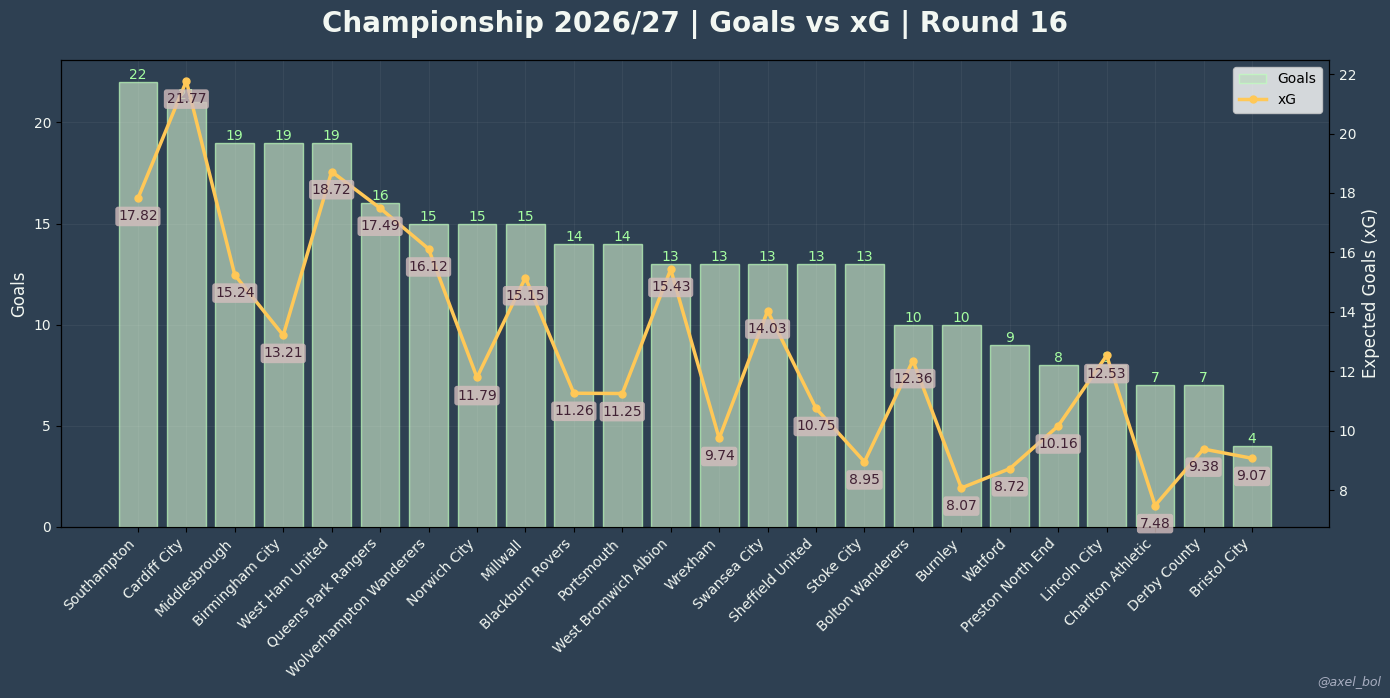

In [ ]:
# WRONG x labels - Goals vs Avg xG

import matplotlib.pyplot as plt

# Ordenar por Avg xG de mayor a menor
c_df_sorted = xG_df.sort_values('home_goals', ascending=False)

# Figura
fig, ax1 = plt.subplots(figsize=(14, 7), facecolor="#2E4052")
ax1.set_facecolor("#2E4052")

# X positions
x = range(len(c_df_sorted))

# --- BAR: Avg xG ---
bars = ax1.bar(
    x,
    c_df_sorted['home_goals'],
    color='#BDD9BF',
    edgecolor='#BFFFBC',
    alpha=0.7,
    label='Goals'
)

# Valores encima de las barras
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height}',
        #f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        color='#A6FFA1'
    )

# Eje izquierdo
#ax1.set_xlabel('Team Name', fontsize=12, fontweight='bold')
ax1.set_ylabel('Goals', fontsize=12, color='#F2F7F2')
ax1.tick_params(axis='y', labelcolor='#F2F7F2')

# --- LINE: Goals ---
ax2 = ax1.twinx()

ax2.plot(
    x,
    c_df_sorted['xG_home'],
    color='#FFC857',
    marker='o',
    markersize=5,
    linewidth=2.5,
    linestyle='-',
    label='xG'
)

# For que añade los valores encima de cada punto
for i, goals in enumerate(c_df_sorted['xG_home']):
    plt.annotate(
        # texto a mostrar
        f"{goals:.2f}",
        # posición del punto (índice, valor)
        xy=(i, goals),
        # desplazamiento en puntos (x, y)
        xytext=(0, -8),
        textcoords='offset points',
        ha='center',
        va='top',
        fontsize=10,
        #fontweight='bold',
        color='#412234',
        bbox=dict(boxstyle='round,pad=0.2', fc='#D4BEBE', ec='none', alpha=0.8)
    )

# Eje derecho
ax2.set_ylabel('Expected Goals (xG)', fontsize=12, color='#F2F7F2')
ax2.tick_params(axis='y', labelcolor='#F2F7F2')

# Nombres de equipos
ax1.set_xticks(x)
ax1.set_xticklabels(
    c_df_sorted['homeTeamName'],
    rotation=45,
    ha='right',
    color='#F2F7F2'
)

# Título
plt.title(
    'Championship 2026/27 | Goals vs xG | Round 16',
    fontsize=20,
    fontweight='bold',
    pad=20,
    color='#F2F7F2'
)

# Grid solamente para goals
ax1.grid(
    True,
    axis='both',
    alpha=0.05,
    color='#FFFFFF'
)

# Combinar las leyendas de ambos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper right',
    frameon=True
)

# Firma
plt.figtext(
    0.99,
    0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#A8AEC1',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/wrongxGvsGoals.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=False)
plt.show()

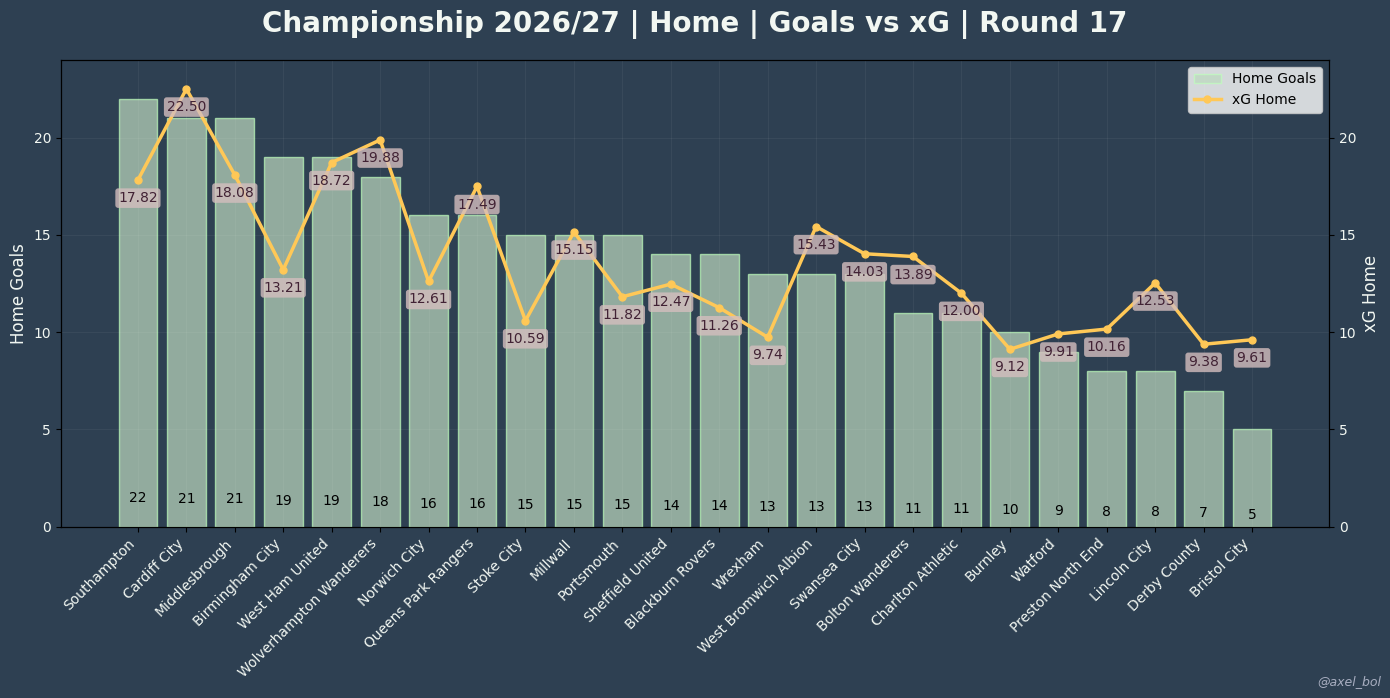

In [ ]:
# HOME goals vs xG

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Ordenar por Avg xG de mayor a menor
c_df_sorted = xG_h_df.sort_values('home_goals', ascending=False)

# Calcular el máximo entre goals y total_xG, redondear hacia arriba al siguiente múltiplo de 5 y sumar 5
max_value = max(c_df_sorted['home_goals'].max(), c_df_sorted['xG_home'].max())
y_max = (int(max_value) // 1 + 1) * 1 + 1

# Figura
fig, ax1 = plt.subplots(figsize=(14, 7), facecolor="#2E4052")
ax1.set_facecolor("#2E4052")

# X positions
x = range(len(c_df_sorted))

# --- BAR: Avg xG ---
bars = ax1.bar(
    x,
    c_df_sorted['home_goals'],
    color='#BDD9BF',
    edgecolor='#BFFFBC',
    alpha=0.7,
    label='Home Goals'
)

# Valores encima de las barras
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height * 0.05,
        f'{height}',
        #f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        #color='#A6FFA1'
        color='black'
    )

# Eje izquierdo
#ax1.set_xlabel('Team Name', fontsize=12, fontweight='bold')
ax1.set_ylabel('Home Goals', fontsize=12, color='#F2F7F2')
ax1.tick_params(axis='y', labelcolor='#F2F7F2')

# Configurar eje Y de Goals: de 5 en 5 hasta y_max
ax1.set_ylim(0, y_max)
ax1.yaxis.set_major_locator(MultipleLocator(5))

# --- LINE: xG ---
ax2 = ax1.twinx()

ax2.plot(
    x,
    c_df_sorted['xG_home'],
    color='#FFC857',
    marker='o',
    markersize=5,
    linewidth=2.5,
    linestyle='-',
    label='xG Home'
)

# For que añade los valores encima de cada punto
for i, total_xG in enumerate(c_df_sorted['xG_home']):
    plt.annotate(
        # texto a mostrar
        f"{total_xG:.2f}",
        # posición del punto (índice, valor)
        xy=(i, total_xG),
        # desplazamiento en puntos (x, y)
        xytext=(0, -8),
        textcoords='offset points',
        ha='center',
        va='top',
        fontsize=10,
        #fontweight='bold',
        color='#412234',
        bbox=dict(boxstyle='round,pad=0.2', fc='#D4BEBE', ec='none', alpha=0.8)
    )

# Eje derecho
ax2.set_ylabel('xG Home', fontsize=12, color='#F2F7F2')
ax2.tick_params(axis='y', labelcolor='#F2F7F2')

# Configurar eje Y de xG: de 5 en 5 hasta y_max
ax2.set_ylim(0, y_max)
ax2.yaxis.set_major_locator(MultipleLocator(5))

# Nombres de equipos
ax1.set_xticks(x)
ax1.set_xticklabels(
    c_df_sorted['homeTeamName'],
    rotation=45,
    ha='right',
    color='#F2F7F2'
)

# Título
plt.title(
    'Championship 2026/27 | Home | Goals vs xG | Round 17',
    fontsize=20,
    fontweight='bold',
    pad=20,
    color='#F2F7F2'
)

# Grid solamente para total_xG
ax1.grid(
    True,
    axis='both',
    alpha=0.05,
    color='#FFFFFF'
)

# Combinar las leyendas de ambos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper right',
    frameon=True
)

# Firma
plt.figtext(
    0.99,
    0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#A8AEC1',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/rightxGvsGoals.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=False)
plt.show()

In [ ]:
# AWAY get only teams with bigger xG than goals
xG_a_df[xG_a_df['xG_away'] < xG_a_df['away_goals']]

,awayTeamName,away_goals,xG_away
21,West Ham United,19,16.34
11,Norwich City,19,14.76
4,Burnley,14,12.72
17,Stoke City,12,7.78
15,Sheffield United,12,9.91
1,Blackburn Rovers,11,8.50
2,Bolton Wanderers,11,9.94
12,Portsmouth,7,6.66
